# TRƯỜNG ĐẠI HỌC KINH TẾ - KỸ THUẬT CÔNG NGHIỆP (UNETI)
## KHOA KHOA HỌC ỨNG DỤNG - BỘ MÔN TOÁN & KHOA HỌC DỮ LIỆU
---
### BÁO CÁO THỰC HÀNH ĐỒ ÁN 1
**ĐỀ TÀI: SỬ DỤNG NGÔN NGỮ PYTHON, R ĐỂ PHÂN TÍCH NHÂN KHẨU HỌC VÀ DỰ ĐOÁN MỨC THU NHẬP CÁ NHÂN (US ADULT CENSUS)**

* **Sinh viên thực hiện:** **NGUYỄN VĂN DŨNG**
* **Mã sinh viên:** `22174600097`
* **Lớp:** `DHKL18A1HN` (Nhóm: 1_2)
* **Giảng viên hướng dẫn:** ThS. Trần Chí Lê

---
### NỘI DUNG NHIỆM VỤ PHỤ TRÁCH TRONG ĐỒ ÁN:
1. **Nhiệm vụ 1 (Task 4):** Trực quan hóa phân phối đơn biến & Phát hiện ngoại lai (Outliers) cho 5 biến định lượng (`age`, `education.num`, `hours.per.week`, `capital.gain`, `capital.loss`).
2. **Nhiệm vụ 2 (Task 6):** Trực quan nhóm tỷ lệ lồng nhau (Nested Proportions - 100% Stacked Bar Charts).
3. **Nhiệm vụ 3 (Task 7):** Khảo sát mối liên hệ đa biến & Kiểm định tính độc lập Chi-Square ($lpha = 0.05$).


## 0. Thiết lập môi trường và nạp dữ liệu


In [1]:
# 1. Import các thư viện phân tích & trực quan hóa dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

# Cấu hình giao diện đồ thị chuyên nghiệp
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
%matplotlib inline

print("Đã tải thành công các thư viện!")


Đã tải thành công các thư viện!


In [2]:
# 2. Đọc bộ dữ liệu Adult Census Income trực tiếp từ kho lưu trữ
# Nguồn dữ liệu hỗ trợ đọc online khi chạy trên Google Colab
data_url = "https://raw.githubusercontent.com/NguyenVanDung0097-DHKL16A2HN/DoAn1-Uneti/main/data/adult_cleaned.csv"

try:
    df = pd.read_csv(data_url)
    print(f"Tải dữ liệu từ GitHub thành công: {df.shape[0]} dòng, {df.shape[1]} cột")
except Exception as e:
    print("Tải dữ liệu từ local file...")
    df = pd.read_csv("../data/adult_cleaned.csv")
    print(f"Kích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")

# Tạo bản sao df_model để thực hiện phân tích
df_model = df.copy()

# Đảm bảo tên cột tương thích chuẩn cả dạng dot '.' và underscore '_'
if 'education.num' not in df_model.columns and 'education_num' in df_model.columns:
    df_model['education.num'] = df_model['education_num']
    df_model['hours.per.week'] = df_model['hours_per_week']
    df_model['capital.gain'] = df_model['capital_gain']
    df_model['capital.loss'] = df_model['capital_loss']
    df_model['marital.status'] = df_model['marital_status']

df_model.head(5)


Tải dữ liệu từ GitHub thành công: 32537 dòng, 16 cột


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,...,capital_loss,hours_per_week,native_country,income,income_num,education.num,hours.per.week,capital.gain,capital.loss,marital.status
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,...,4356,40,United-States,<=50K,0,9,40,0,4356,Widowed
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,...,4356,18,United-States,<=50K,0,9,18,0,4356,Widowed
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,...,4356,40,United-States,<=50K,0,10,40,0,4356,Widowed
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,...,3900,40,United-States,<=50K,0,4,40,0,3900,Divorced
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,...,3900,40,United-States,<=50K,0,10,40,0,3900,Separated


# Chương 1: Trực quan hóa phân phối đơn biến (Nhiệm vụ 4 - Nguyễn Văn Dũng)
Mục tiêu:
- Tính toán các chỉ số thống kê mô tả (Mean, Min, Max, Median, Std, IQR).
- Vẽ bộ 4 biểu đồ `(2, 2)` chuẩn form Google Colab gồm: Histogram, Density Plot, Boxplot tổng thể và Boxplot so sánh theo nhóm thu nhập (`<=50K`, `>50K`).
- Tìm ra các điểm dữ liệu bất thường (Outliers).


### 1.1. Phân tích độ tuổi (age)


In [3]:
# Thống kê chi tiết cho biến tuổi
print("THỐNG KÊ CHI TIẾT - TUỔI (AGE):")
print("=" * 70)
age_stats = df_model['age'].describe()
print(age_stats)
print(f"\nTrung vị (Median): {df_model['age'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['age'].std():.2f}")
iqr_age = df_model['age'].quantile(0.75) - df_model['age'].quantile(0.25)
print(f"Khoảng tứ phân vị (IQR): {iqr_age:.1f}")


THỐNG KÊ CHI TIẾT - TUỔI (AGE):
count    32537.000000
mean        38.585549
std         13.637984
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

Trung vị (Median): 37.0
Độ lệch chuẩn (Std): 13.64
Khoảng tứ phân vị (IQR): 20.0


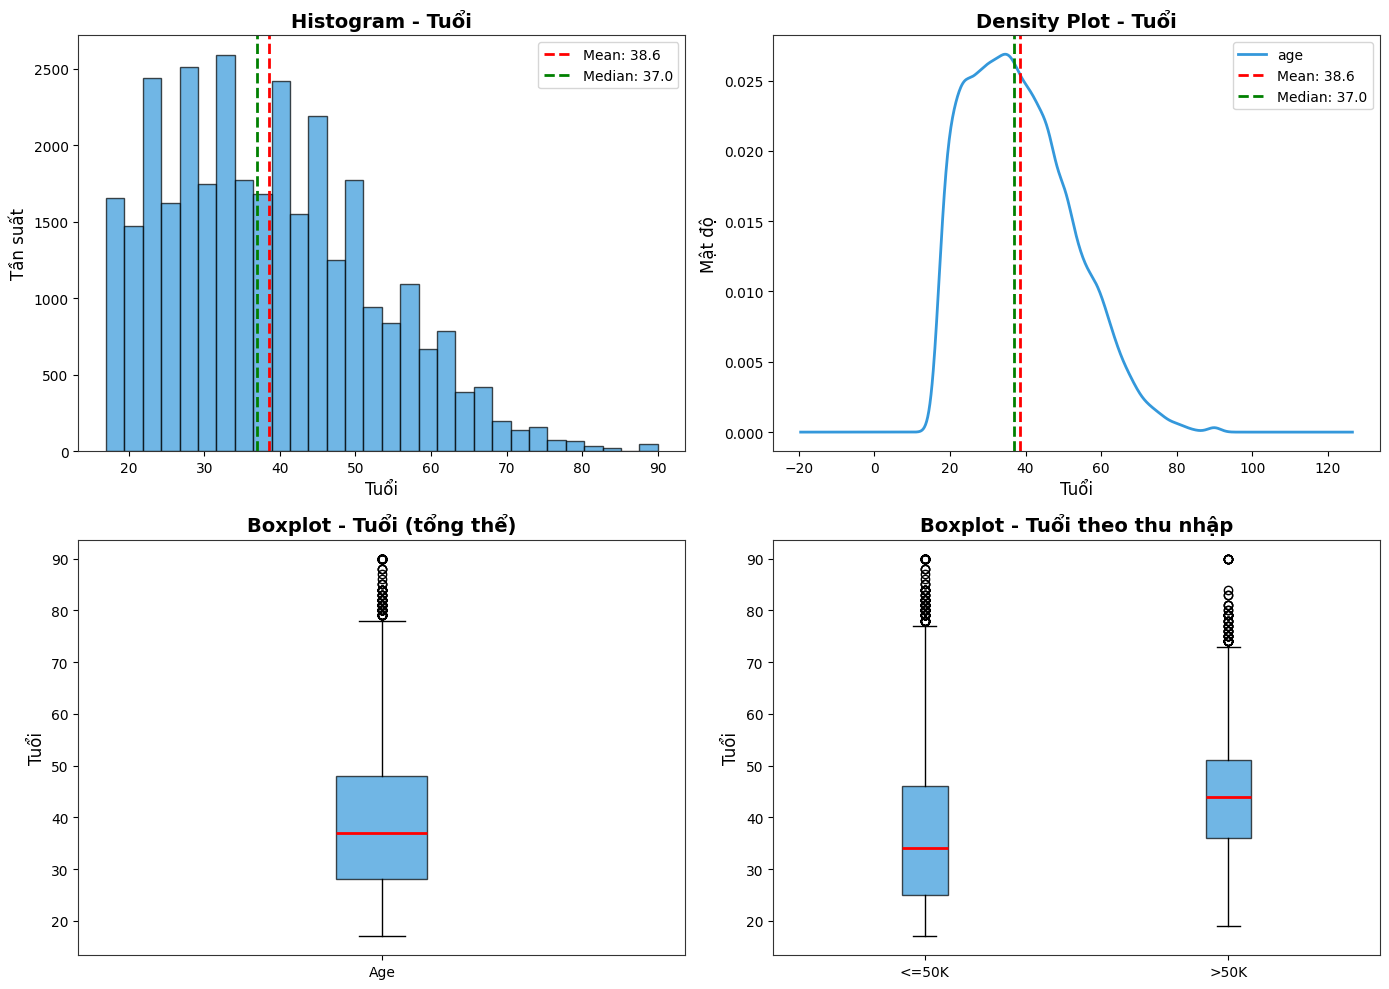


NHẬN XÉT (NGUYỄN VĂN DŨNG):
- Phân phối tuổi lệch phải (right-skewed) với độ tuổi trung bình là 38.6 tuổi, trung vị là 37 tuổi.
- Đa số lực lượng lao động tập trung ở độ tuổi thanh niên và trung niên (từ 25 đến 45 tuổi).
- Người có thu nhập >50K có độ tuổi trung bình (44.3 tuổi) lớn hơn rõ rệt so với người có thu nhập <=50K (36.8 tuổi).
- Phát hiện một số điểm ngoại lai (Outliers) ở độ tuổi cao (> 78 tuổi).


In [4]:
# Vẽ Histogram, Density Plot và Boxplot cho tuổi
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
axes[0, 0].hist(df_model['age'], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["age"].mean():.1f}')
axes[0, 0].axvline(df_model['age'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_model["age"].median():.1f}')
axes[0, 0].set_title('Histogram - Tuổi', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Tuổi', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# 2. Density Plot
df_model['age'].plot(kind='density', ax=axes[0, 1], color='#3498db', linewidth=2)
axes[0, 1].axvline(df_model['age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["age"].mean():.1f}')
axes[0, 1].axvline(df_model['age'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_model["age"].median():.1f}')
axes[0, 1].set_title('Density Plot - Tuổi', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Tuổi', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['age'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#3498db', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Tuổi (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Tuổi', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Age'])

# 4. Boxplot theo thu nhập
age_by_income = [df_model[df_model['income'] == '<=50K']['age'],
                 df_model[df_model['income'] == '>50K']['age']]
axes[1, 1].boxplot(age_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#3498db', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Tuổi theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Tuổi', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG):")
print("- Phân phối tuổi lệch phải (right-skewed) với độ tuổi trung bình là 38.6 tuổi, trung vị là 37 tuổi.")
print("- Đa số lực lượng lao động tập trung ở độ tuổi thanh niên và trung niên (từ 25 đến 45 tuổi).")
print("- Người có thu nhập >50K có độ tuổi trung bình (44.3 tuổi) lớn hơn rõ rệt so với người có thu nhập <=50K (36.8 tuổi).")
print("- Phát hiện một số điểm ngoại lai (Outliers) ở độ tuổi cao (> 78 tuổi).")


### 1.2. Phân tích số năm học vấn (education.num)


In [5]:
# Thống kê chi tiết cho biến education.num
print("THỐNG KÊ CHI TIẾT - SỐ NĂM HỌC VẤN (EDUCATION.NUM):")
print("=" * 70)
edu_stats = df_model['education.num'].describe()
print(edu_stats)
print(f"\nTrung vị (Median): {df_model['education.num'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['education.num'].std():.2f}")
iqr_edu = df_model['education.num'].quantile(0.75) - df_model['education.num'].quantile(0.25)
print(f"Khoảng tứ phân vị (IQR): {iqr_edu:.1f}")


THỐNG KÊ CHI TIẾT - SỐ NĂM HỌC VẤN (EDUCATION.NUM):
count    32537.000000
mean        10.081815
std          2.571633
min          1.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         16.000000
Name: education.num, dtype: float64

Trung vị (Median): 10.0
Độ lệch chuẩn (Std): 2.57
Khoảng tứ phân vị (IQR): 3.0


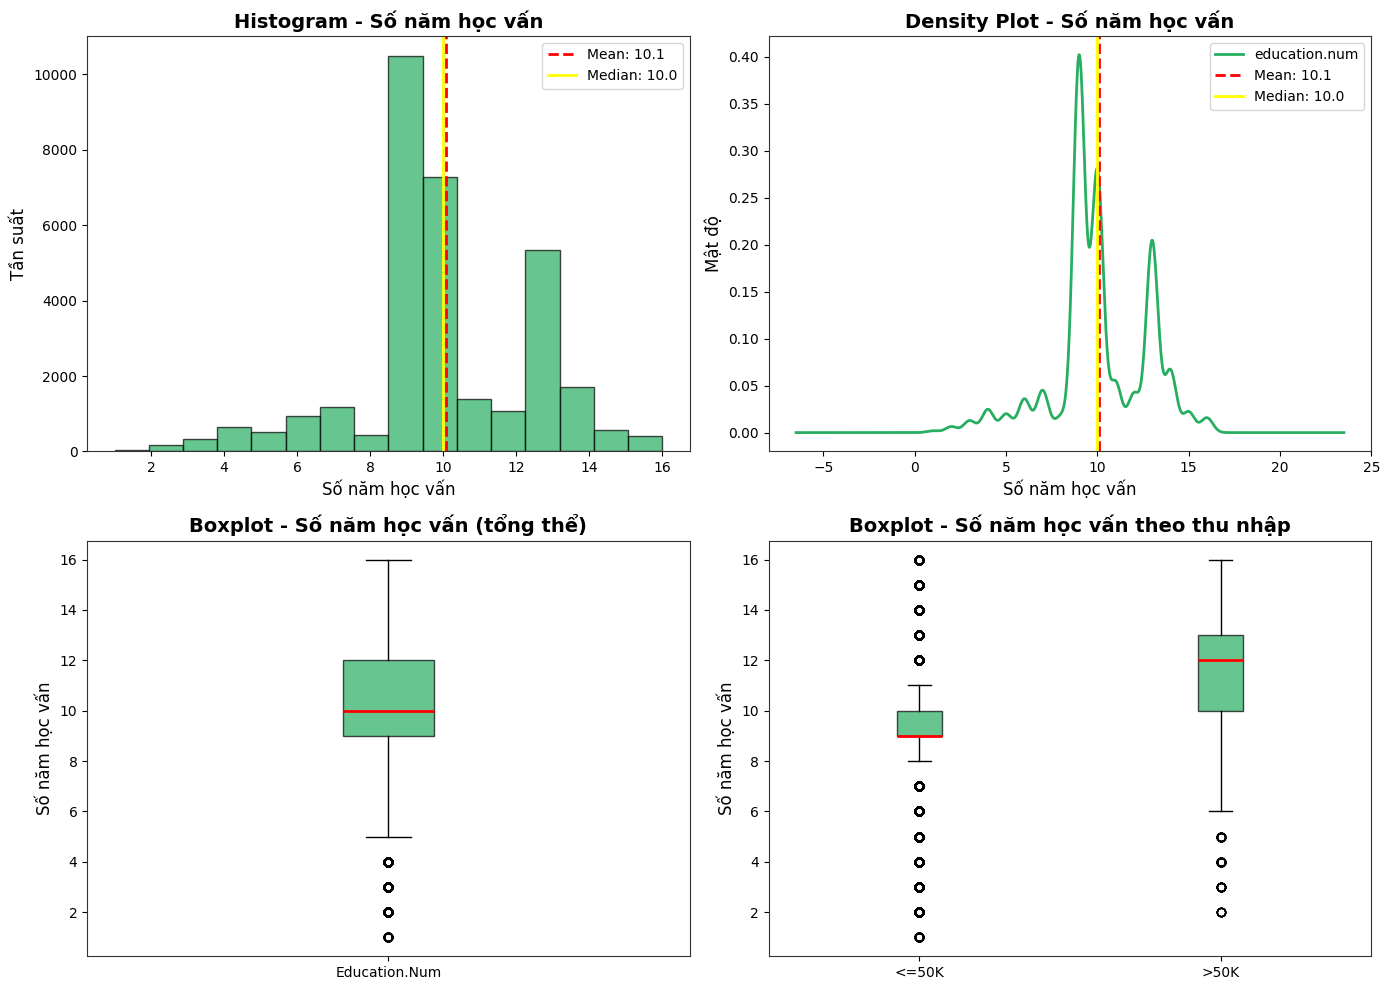


NHẬN XÉT (NGUYỄN VĂN DŨNG):
- Số năm học vấn bình quân: 10.1 năm; trung vị: 10.0 năm.
- Đỉnh phân phối xuất hiện tại mốc 9 năm (HS-grad tốt nghiệp cấp 3) và 13 năm (Bachelors cử nhân đại học).
- Sự tương phản rõ rệt: Nhóm thu nhập >50K có trung vị học vấn là 12 năm, vượt trội so với 9 năm của nhóm <=50K.
- Trình độ học vấn là nhân tố phân loại mạnh mẽ nhất đối với bài toán dự đoán thu nhập.


In [6]:
# Vẽ Histogram, Density Plot và Boxplot cho education.num
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
axes[0, 0].hist(df_model['education.num'], bins=16, color='#27ae60', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['education.num'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["education.num"].mean():.1f}')
axes[0, 0].axvline(df_model['education.num'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["education.num"].median():.1f}')
axes[0, 0].set_title('Histogram - Số năm học vấn', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Số năm học vấn', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# 2. Density Plot
df_model['education.num'].plot(kind='density', ax=axes[0, 1], color='#27ae60', linewidth=2)
axes[0, 1].axvline(df_model['education.num'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["education.num"].mean():.1f}')
axes[0, 1].axvline(df_model['education.num'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["education.num"].median():.1f}')
axes[0, 1].set_title('Density Plot - Số năm học vấn', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Số năm học vấn', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['education.num'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#27ae60', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Số năm học vấn (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Số năm học vấn', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Education.Num'])

# 4. Boxplot theo thu nhập
edu_by_income = [df_model[df_model['income'] == '<=50K']['education.num'],
                 df_model[df_model['income'] == '>50K']['education.num']]
axes[1, 1].boxplot(edu_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#27ae60', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Số năm học vấn theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Số năm học vấn', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG):")
print("- Số năm học vấn bình quân: 10.1 năm; trung vị: 10.0 năm.")
print("- Đỉnh phân phối xuất hiện tại mốc 9 năm (HS-grad tốt nghiệp cấp 3) và 13 năm (Bachelors cử nhân đại học).")
print("- Sự tương phản rõ rệt: Nhóm thu nhập >50K có trung vị học vấn là 12 năm, vượt trội so với 9 năm của nhóm <=50K.")
print("- Trình độ học vấn là nhân tố phân loại mạnh mẽ nhất đối với bài toán dự đoán thu nhập.")


### 1.3. Phân tích số giờ làm việc mỗi tuần (hours.per.week)


In [7]:
# Thống kê chi tiết cho biến hours.per.week
print("THỐNG KÊ CHI TIẾT - SỐ GIỜ LÀM VIỆC / TUẦN (HOURS.PER.WEEK):")
print("=" * 70)
hpw_stats = df_model['hours.per.week'].describe()
print(hpw_stats)
print(f"\nTrung vị (Median): {df_model['hours.per.week'].median():.1f}")
print(f"Độ lệch chuẩn (Std): {df_model['hours.per.week'].std():.2f}")
iqr_hpw = df_model['hours.per.week'].quantile(0.75) - df_model['hours.per.week'].quantile(0.25)
print(f"Khoảng tứ phân vị (IQR): {iqr_hpw:.1f}")


THỐNG KÊ CHI TIẾT - SỐ GIỜ LÀM VIỆC / TUẦN (HOURS.PER.WEEK):
count    32537.000000
mean        40.440329
std         12.346889
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hours.per.week, dtype: float64

Trung vị (Median): 40.0
Độ lệch chuẩn (Std): 12.35
Khoảng tứ phân vị (IQR): 5.0


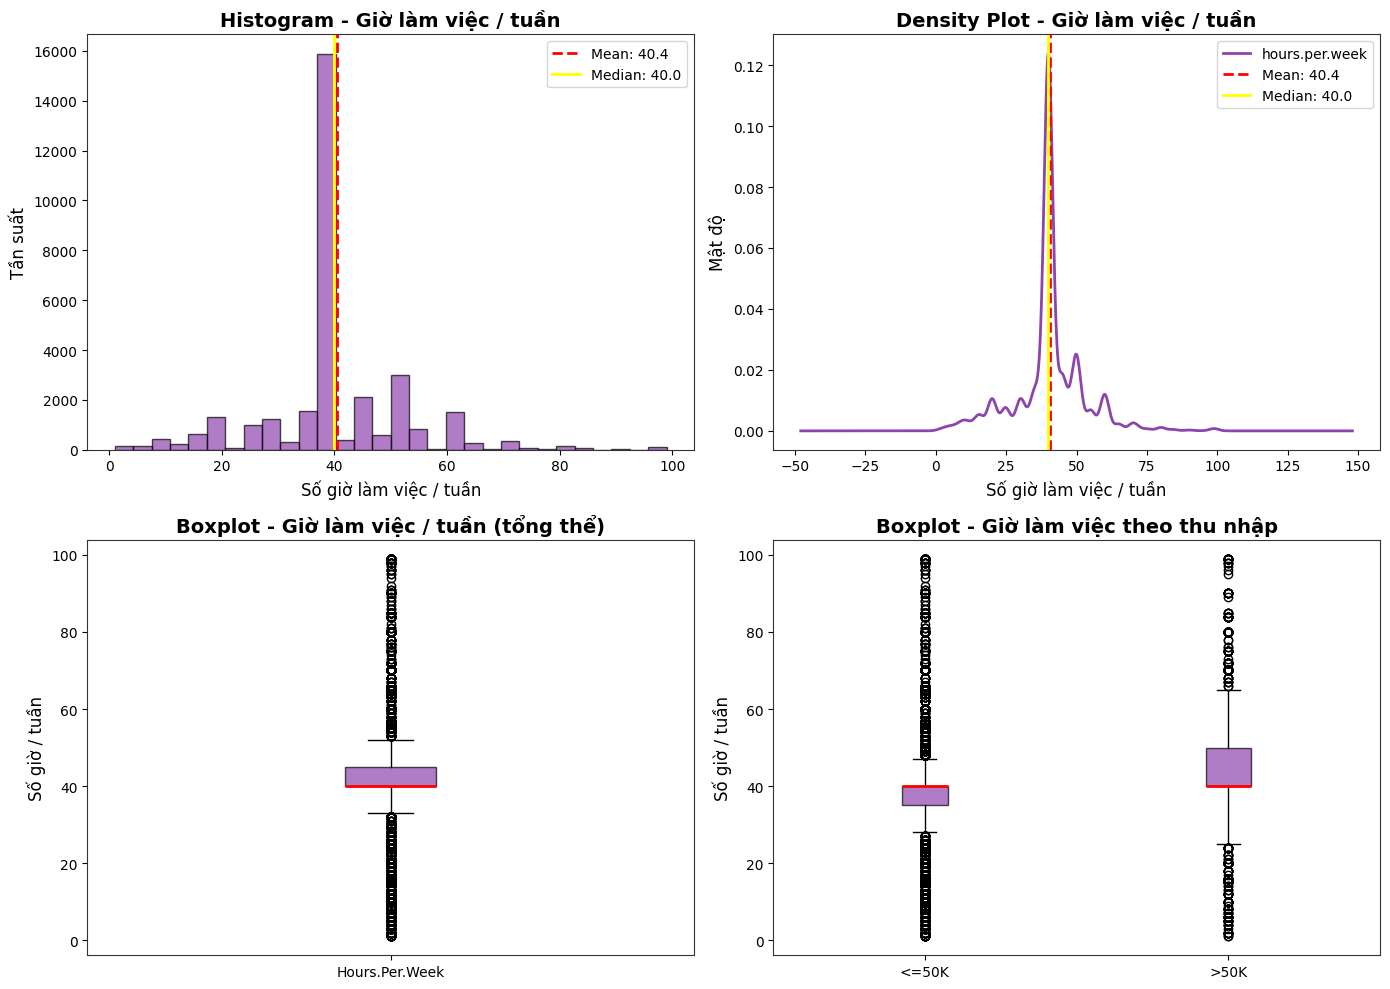


NHẬN XÉT (NGUYỄN VĂN DŨNG):
- Số giờ làm việc bình quân: 40.4 giờ/tuần; trung vị chuẩn xác ở mốc 40.0 giờ/tuần.
- Tỷ lệ ngoại lai rất lớn (~27.7%) xuất phát từ các chế độ làm thêm giờ (> 40h đến tối đa 99h/tuần) và làm việc bán thời gian (< 35h/tuần).
- Nhóm thu nhập >50K làm việc trung bình 45.5 giờ/tuần, cao hơn đáng kể so với 38.8 giờ/tuần của nhóm <=50K.


In [8]:
# Vẽ Histogram, Density Plot và Boxplot cho hours.per.week
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
axes[0, 0].hist(df_model['hours.per.week'], bins=30, color='#8e44ad', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(df_model['hours.per.week'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["hours.per.week"].mean():.1f}')
axes[0, 0].axvline(df_model['hours.per.week'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["hours.per.week"].median():.1f}')
axes[0, 0].set_title('Histogram - Giờ làm việc / tuần', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Số giờ làm việc / tuần', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)
axes[0, 0].legend()

# 2. Density Plot
df_model['hours.per.week'].plot(kind='density', ax=axes[0, 1], color='#8e44ad', linewidth=2)
axes[0, 1].axvline(df_model['hours.per.week'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_model["hours.per.week"].mean():.1f}')
axes[0, 1].axvline(df_model['hours.per.week'].median(), color='yellow', linestyle='-', linewidth=2, label=f'Median: {df_model["hours.per.week"].median():.1f}')
axes[0, 1].set_title('Density Plot - Giờ làm việc / tuần', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Số giờ làm việc / tuần', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)
axes[0, 1].legend()

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['hours.per.week'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#8e44ad', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Giờ làm việc / tuần (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Số giờ / tuần', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Hours.Per.Week'])

# 4. Boxplot theo thu nhập
hpw_by_income = [df_model[df_model['income'] == '<=50K']['hours.per.week'],
                 df_model[df_model['income'] == '>50K']['hours.per.week']]
axes[1, 1].boxplot(hpw_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#8e44ad', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Giờ làm việc theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Số giờ / tuần', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG):")
print("- Số giờ làm việc bình quân: 40.4 giờ/tuần; trung vị chuẩn xác ở mốc 40.0 giờ/tuần.")
print("- Tỷ lệ ngoại lai rất lớn (~27.7%) xuất phát từ các chế độ làm thêm giờ (> 40h đến tối đa 99h/tuần) và làm việc bán thời gian (< 35h/tuần).")
print("- Nhóm thu nhập >50K làm việc trung bình 45.5 giờ/tuần, cao hơn đáng kể so với 38.8 giờ/tuần của nhóm <=50K.")


### 1.4. Phân tích thu nhập từ vốn (capital.gain)


In [9]:
# Thống kê chi tiết cho biến capital.gain
print("THỐNG KÊ CHI TIẾT - THU NHẬP TỪ VỐN (CAPITAL.GAIN):")
print("=" * 70)
print(df_model['capital.gain'].describe())
print(f"\nTỷ lệ người có capital.gain = 0: {(df_model['capital.gain'] == 0).mean() * 100:.2f}%")
print(f"Trung vị (Median): {df_model['capital.gain'].median():.1f}")
print(f"Độ lệch (Skewness): {df_model['capital.gain'].skew():.2f}")


THỐNG KÊ CHI TIẾT - THU NHẬP TỪ VỐN (CAPITAL.GAIN):
count    32537.000000
mean      1078.443741
std       7387.957424
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital.gain, dtype: float64

Tỷ lệ người có capital.gain = 0: 91.66%
Trung vị (Median): 0.0
Độ lệch (Skewness): 11.95


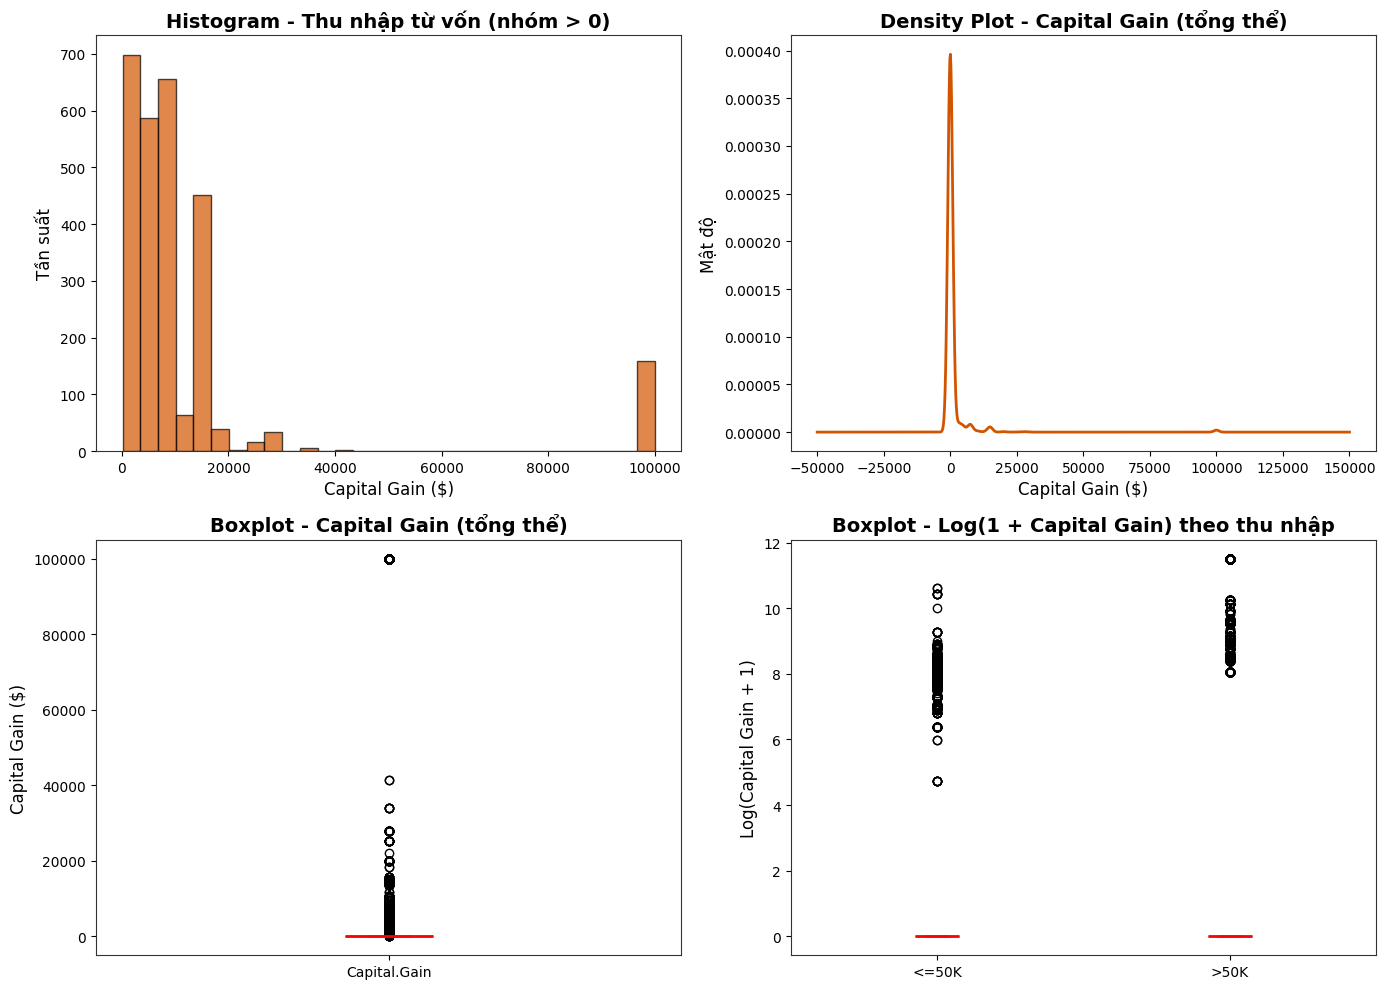


NHẬN XÉT (NGUYỄN VĂN DŨNG):
- Phân phối bị lệch phải cực kỳ nặng nề (Skewness = 11.95), có tới 91.6% quan sát bằng 0.
- Ở nhóm >50K, thu nhập từ vốn trung bình đạt $4.007, trong khi nhóm <=50K chỉ đạt $148.
- Xuất hiện giá trị ngoại lai đặc biệt tại mốc $99.999 (mức trần ghi nhận trong khảo sát).


In [10]:
# Vẽ Histogram, Density Plot và Boxplot cho capital.gain
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram (lọc nhóm > 0 để quan sát rõ phân phối)
axes[0, 0].hist(df_model[df_model['capital.gain'] > 0]['capital.gain'], bins=30, color='#d35400', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Histogram - Thu nhập từ vốn (nhóm > 0)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Capital Gain ($)', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)

# 2. Density Plot
df_model['capital.gain'].plot(kind='density', ax=axes[0, 1], color='#d35400', linewidth=2)
axes[0, 1].set_title('Density Plot - Capital Gain (tổng thể)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Capital Gain ($)', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['capital.gain'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#d35400', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Capital Gain (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Capital Gain ($)', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Capital.Gain'])

# 4. Boxplot theo thu nhập (dùng log1p để trực quan hóa do chênh lệch cực lớn)
cap_by_income = [np.log1p(df_model[df_model['income'] == '<=50K']['capital.gain']),
                 np.log1p(df_model[df_model['income'] == '>50K']['capital.gain'])]
axes[1, 1].boxplot(cap_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#d35400', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Log(1 + Capital Gain) theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Log(Capital Gain + 1)', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG):")
print("- Phân phối bị lệch phải cực kỳ nặng nề (Skewness = 11.95), có tới 91.6% quan sát bằng 0.")
print("- Ở nhóm >50K, thu nhập từ vốn trung bình đạt $4.007, trong khi nhóm <=50K chỉ đạt $148.")
print("- Xuất hiện giá trị ngoại lai đặc biệt tại mốc $99.999 (mức trần ghi nhận trong khảo sát).")


### 1.5. Phân tích khoản lỗ từ vốn (capital.loss)


In [11]:
# Thống kê chi tiết cho biến capital.loss
print("THỐNG KÊ CHI TIẾT - KHOẢN LỖ VỐN (CAPITAL.LOSS):")
print("=" * 70)
print(df_model['capital.loss'].describe())
print(f"\nTỷ lệ người có capital.loss = 0: {(df_model['capital.loss'] == 0).mean() * 100:.2f}%")
print(f"Trung vị (Median): {df_model['capital.loss'].median():.1f}")
print(f"Độ lệch (Skewness): {df_model['capital.loss'].skew():.2f}")


THỐNG KÊ CHI TIẾT - KHOẢN LỖ VỐN (CAPITAL.LOSS):
count    32537.000000
mean        87.368227
std        403.101833
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       4356.000000
Name: capital.loss, dtype: float64

Tỷ lệ người có capital.loss = 0: 95.33%
Trung vị (Median): 0.0
Độ lệch (Skewness): 4.59


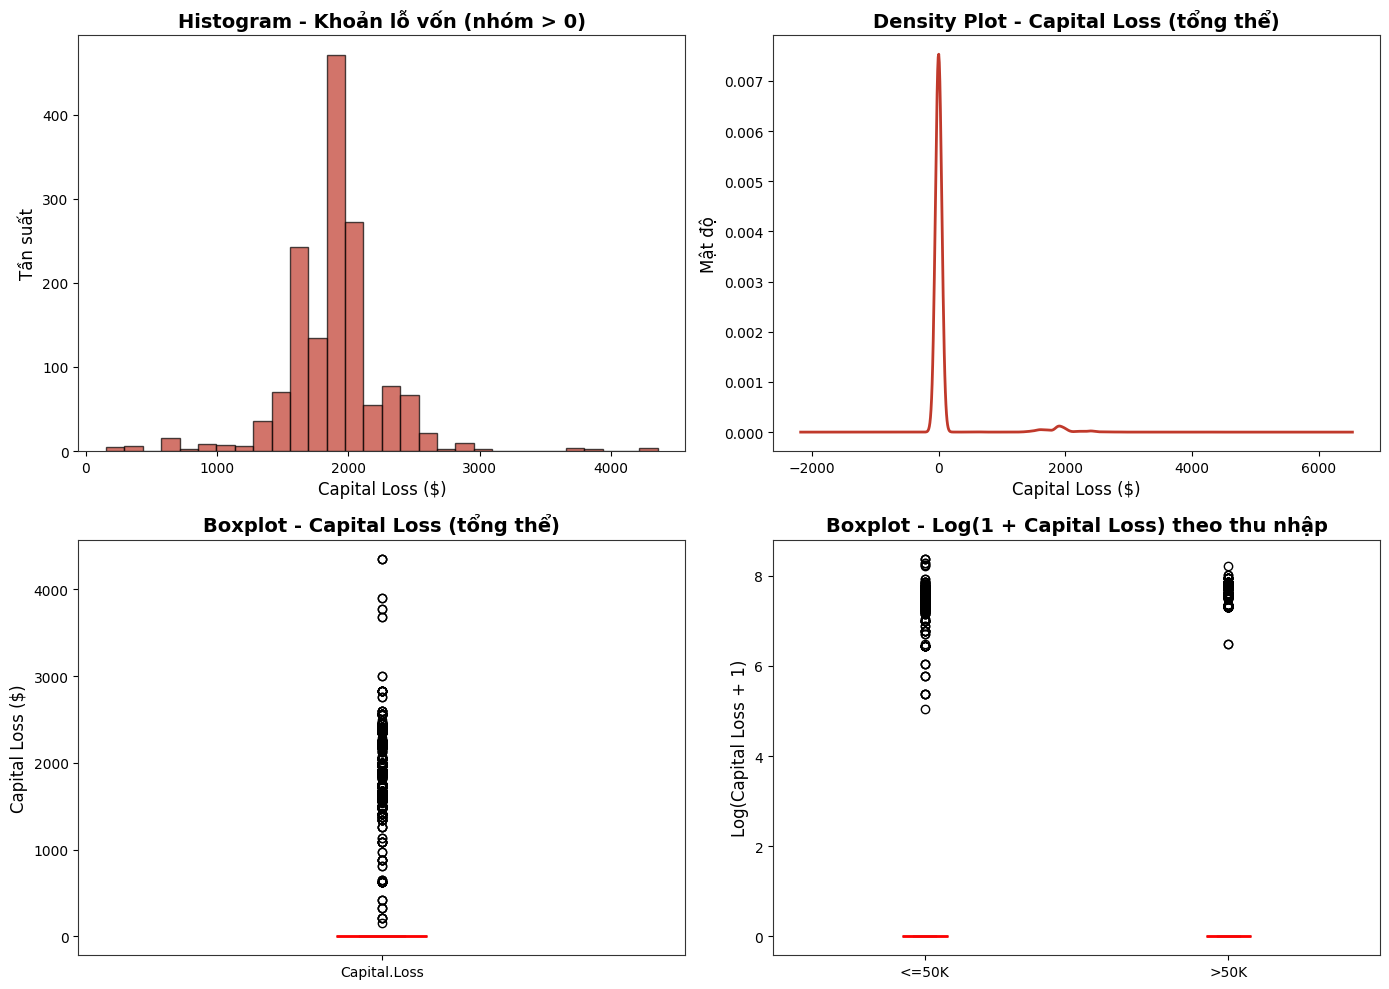


NHẬN XÉT (NGUYỄN VĂN DŨNG):
- Khoảng 95.3% mẫu có giá trị capital.loss = 0.
- Nhóm >50K có khoản lỗ vốn trung bình (~$195) cao hơn nhóm <=50K (~$53), phản ánh tỷ lệ tham gia đầu tư tài chính tích cực hơn của nhóm có điều kiện kinh tế.


In [12]:
# Vẽ Histogram, Density Plot và Boxplot cho capital.loss
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram (nhóm > 0)
axes[0, 0].hist(df_model[df_model['capital.loss'] > 0]['capital.loss'], bins=30, color='#c0392b', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Histogram - Khoản lỗ vốn (nhóm > 0)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Capital Loss ($)', fontsize=12)
axes[0, 0].set_ylabel('Tần suất', fontsize=12)

# 2. Density Plot
df_model['capital.loss'].plot(kind='density', ax=axes[0, 1], color='#c0392b', linewidth=2)
axes[0, 1].set_title('Density Plot - Capital Loss (tổng thể)', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Capital Loss ($)', fontsize=12)
axes[0, 1].set_ylabel('Mật độ', fontsize=12)

# 3. Boxplot tổng thể
axes[1, 0].boxplot(df_model['capital.loss'], vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#c0392b', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_title('Boxplot - Capital Loss (tổng thể)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Capital Loss ($)', fontsize=12)
axes[1, 0].set_xticks([1])
axes[1, 0].set_xticklabels(['Capital.Loss'])

# 4. Boxplot theo thu nhập
cap_loss_by_income = [np.log1p(df_model[df_model['income'] == '<=50K']['capital.loss']),
                      np.log1p(df_model[df_model['income'] == '>50K']['capital.loss'])]
axes[1, 1].boxplot(cap_loss_by_income, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='#c0392b', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 1].set_title('Boxplot - Log(1 + Capital Loss) theo thu nhập', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Log(Capital Loss + 1)', fontsize=12)
axes[1, 1].set_xticks([1, 2])
axes[1, 1].set_xticklabels(['<=50K', '>50K'])

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG):")
print("- Khoảng 95.3% mẫu có giá trị capital.loss = 0.")
print("- Nhóm >50K có khoản lỗ vốn trung bình (~$195) cao hơn nhóm <=50K (~$53), phản ánh tỷ lệ tham gia đầu tư tài chính tích cực hơn của nhóm có điều kiện kinh tế.")


### 1.6. Bảng tổng hợp các giá trị ngoại lai (Outliers) theo quy tắc 1.5 * IQR


In [13]:
# Thống kê Outliers tổng hợp cho tất cả 5 biến định lượng
num_cols = ['age', 'education.num', 'hours.per.week', 'capital.gain', 'capital.loss']
outlier_list = []

for col in num_cols:
    s = df_model[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_count = ((s < lower_bound) | (s > upper_bound)).sum()
    
    outlier_list.append({
        'Biến định lượng': col,
        'Mean': round(s.mean(), 2),
        'Median': round(s.median(), 2),
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Ngưỡng dưới': round(lower_bound, 2),
        'Ngưỡng trên': round(upper_bound, 2),
        'Số Outliers': outliers_count,
        'Tỷ lệ Outliers (%)': round(outliers_count / len(s) * 100, 2)
    })

df_outliers = pd.DataFrame(outlier_list)
print("BẢNG TỔNG HỢP NGOẠI LAI (OUTLIERS):")
display(df_outliers)


BẢNG TỔNG HỢP NGOẠI LAI (OUTLIERS):


,Biến định lượng,Mean,Median,Q1 (25%),Q3 (75%),IQR,Ngưỡng dưới,Ngưỡng trên,Số Outliers,Tỷ lệ Outliers (%)
0,age,38.59,37.0,28.0,48.0,20.0,-2.0,78.0,142,0.44
1,education.num,10.08,10.0,9.0,12.0,3.0,4.5,16.5,1193,3.67
2,hours.per.week,40.44,40.0,40.0,45.0,5.0,32.5,52.5,9002,27.67
3,capital.gain,1078.44,0.0,0.0,0.0,0.0,0.0,0.0,2712,8.34
4,capital.loss,87.37,0.0,0.0,0.0,0.0,0.0,0.0,1519,4.67


# Chương 2: Phân tích nhóm tỷ lệ lồng nhau (Nhiệm vụ 6 - Nguyễn Văn Dũng & Cao Nguyên Ngọc)
Mục tiêu: Phân tích sâu sự khác biệt về tỷ lệ thu nhập `>50K` khi kết hợp đồng thời 2 hoặc nhiều biến nhân khẩu học qua biểu đồ 100% Stacked Bar Chart.


### 2.1. Kết hợp Trình độ học vấn & Giới tính (Education × Sex)


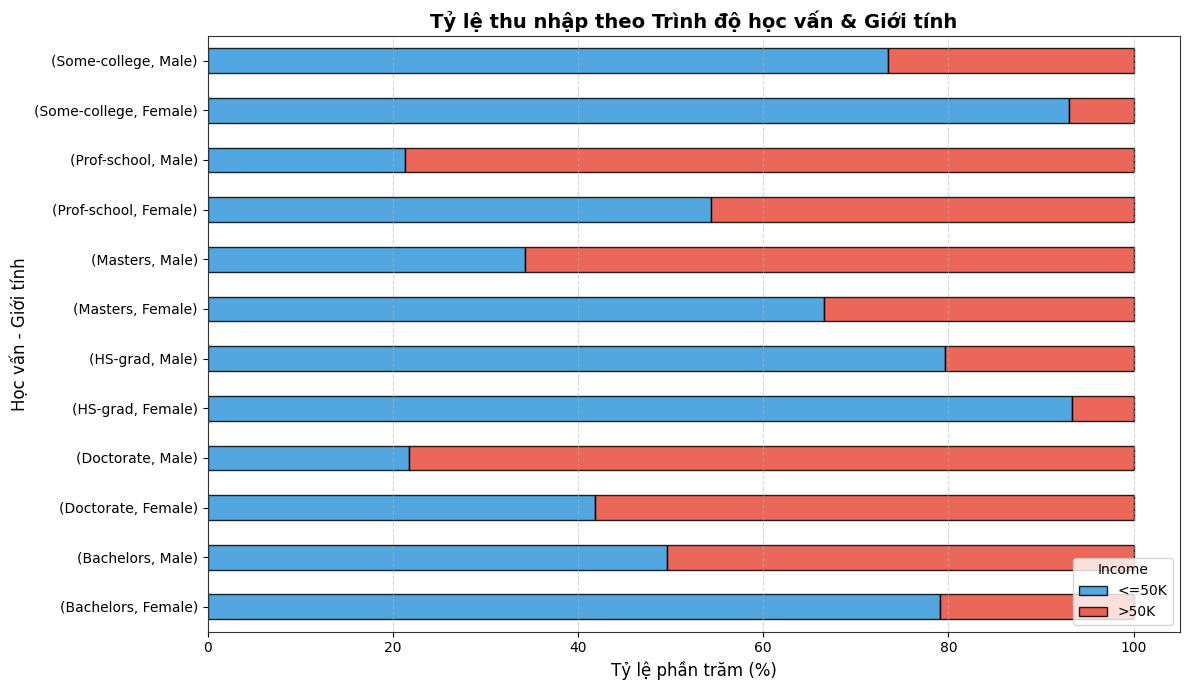


NHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):
- Ở mọi trình độ học vấn, tỷ lệ nam giới đạt thu nhập >50K luôn cao hơn nữ giới.
- Bằng cấp cao (Masters, Doctorate, Prof-school) giúp nâng mạnh tỷ lệ thu nhập cao cho cả hai giới (nam đạt trên 70%, nữ đạt trên 40%).


In [14]:
# Bảng chéo và biểu đồ cột chồng 100% cho Education x Sex
ct_edu_sex = pd.crosstab(index=[df_model['education'], df_model['sex']], columns=df_model['income'], normalize='index') * 100

top_edus = ['HS-grad', 'Some-college', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate']
ct_sub = ct_edu_sex.loc[ct_edu_sex.index.get_level_values(0).isin(top_edus)]

fig, ax = plt.subplots(figsize=(12, 7))
ct_sub.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Trình độ học vấn & Giới tính', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Học vấn - Giới tính', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):")
print("- Ở mọi trình độ học vấn, tỷ lệ nam giới đạt thu nhập >50K luôn cao hơn nữ giới.")
print("- Bằng cấp cao (Masters, Doctorate, Prof-school) giúp nâng mạnh tỷ lệ thu nhập cao cho cả hai giới (nam đạt trên 70%, nữ đạt trên 40%).")


### 2.2. Kết hợp Nghề nghiệp & Giới tính (Occupation × Sex)


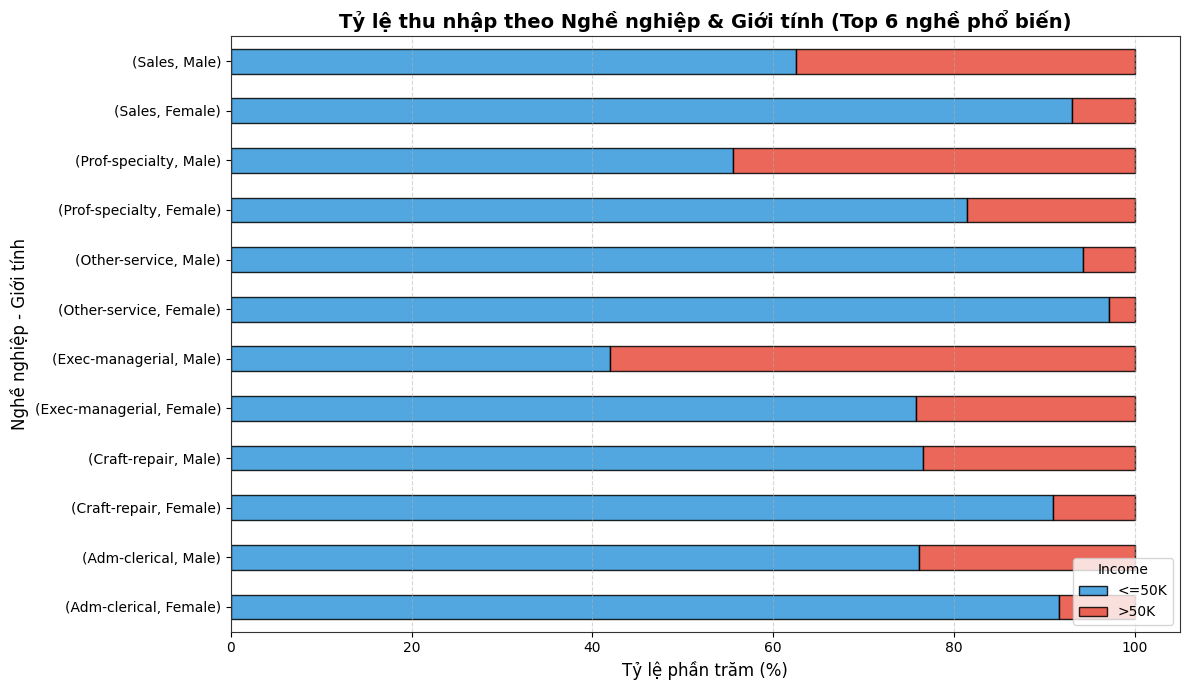


NHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):
- Các ngành nghề điều hành quản lý (Exec-managerial) và chuyên gia chuyên môn (Prof-specialty) tập trung tỷ lệ >50K cao nhất.
- Khối văn phòng hành chính (Adm-clerical) và dịch vụ khác có tỷ lệ thu nhập cao rất thấp.


In [15]:
# Bảng chéo và biểu đồ cột chồng 100% cho Occupation x Sex
top_6_occ = df_model['occupation'].value_counts().head(6).index
df_occ_sub = df_model[df_model['occupation'].isin(top_6_occ)]

ct_occ_sex = pd.crosstab(index=[df_occ_sub['occupation'], df_occ_sub['sex']], columns=df_occ_sub['income'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 7))
ct_occ_sex.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Nghề nghiệp & Giới tính (Top 6 nghề phổ biến)', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Nghề nghiệp - Giới tính', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):")
print("- Các ngành nghề điều hành quản lý (Exec-managerial) và chuyên gia chuyên môn (Prof-specialty) tập trung tỷ lệ >50K cao nhất.")
print("- Khối văn phòng hành chính (Adm-clerical) và dịch vụ khác có tỷ lệ thu nhập cao rất thấp.")


### 2.3. Kết hợp Trình độ học vấn & Tình trạng hôn nhân (Education × Marital Status)


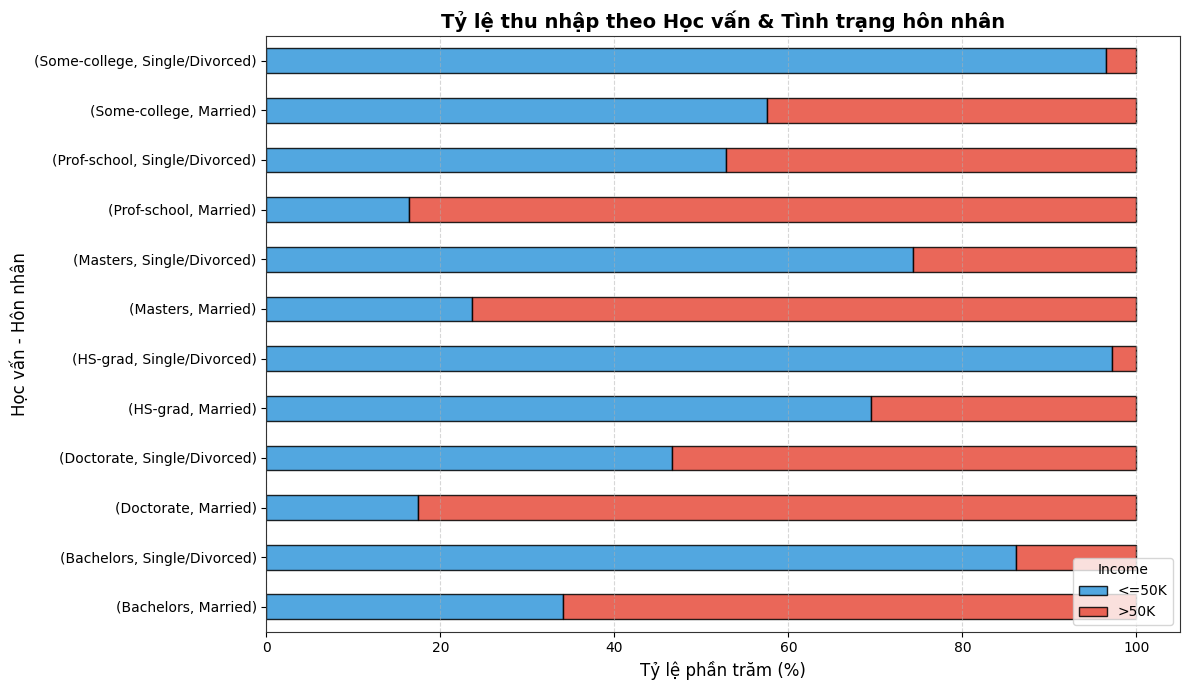


NHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):
- Tình trạng hôn nhân có tác động đòn bẩy rất lớn: Người đã kết hôn (Married) có trình độ đại học trở lên đạt tỷ lệ thu nhập >50K lên đến hơn 65%.


In [16]:
# Phân nhóm hôn nhân: Married vs Single/Divorced
df_model['is_married'] = df_model['marital.status'].apply(lambda x: 'Married' if 'Married' in str(x) else 'Single/Divorced')

ct_edu_mar = pd.crosstab(index=[df_model['education'], df_model['is_married']], columns=df_model['income'], normalize='index') * 100
ct_edu_mar_sub = ct_edu_mar.loc[ct_edu_mar.index.get_level_values(0).isin(top_edus)]

fig, ax = plt.subplots(figsize=(12, 7))
ct_edu_mar_sub.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Học vấn & Tình trạng hôn nhân', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Học vấn - Hôn nhân', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):")
print("- Tình trạng hôn nhân có tác động đòn bẩy rất lớn: Người đã kết hôn (Married) có trình độ đại học trở lên đạt tỷ lệ thu nhập >50K lên đến hơn 65%.")


### 2.4. Kết hợp Nghề nghiệp & Khung giờ làm việc (Occupation × Hours Group)


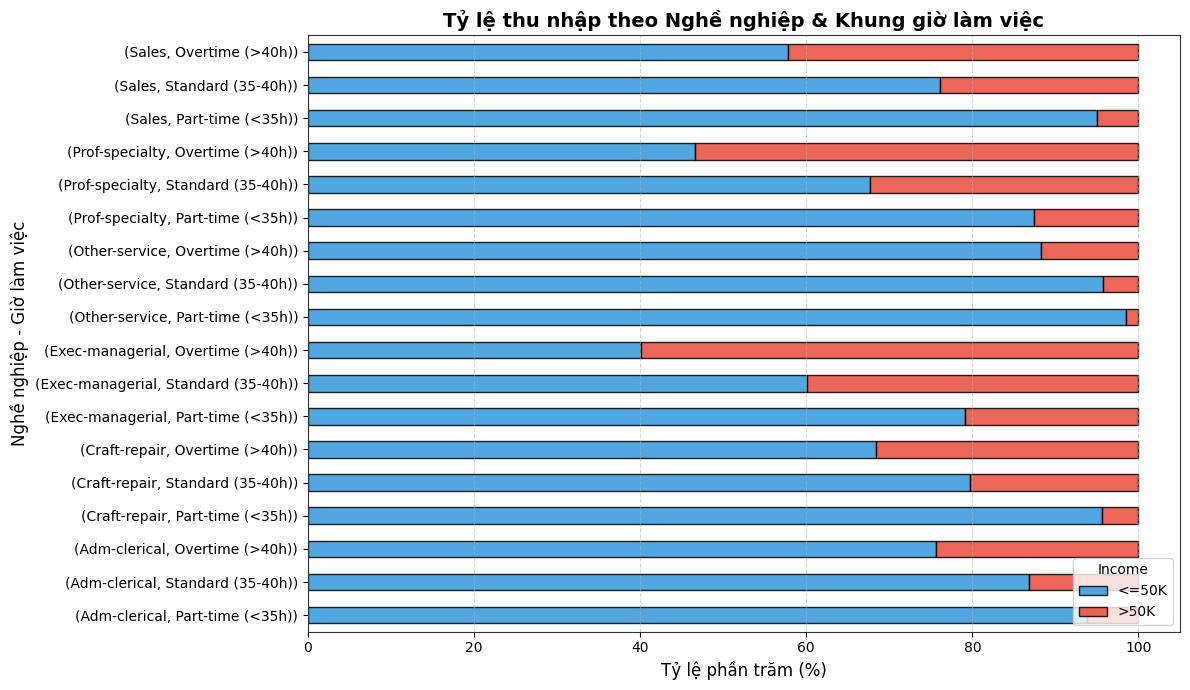


NHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):
- Những người làm việc trong ngành điều hành quản lý kết hợp chế độ làm việc tăng ca (>40h/tuần) có xác suất đạt >50K cao nhất.


In [17]:
# Phân nhóm giờ làm việc: Part-time (<35h), Standard (35-40h), Overtime (>40h)
df_model['hours_group'] = pd.cut(
    df_model['hours.per.week'],
    bins=[0, 34, 40, 100],
    labels=['Part-time (<35h)', 'Standard (35-40h)', 'Overtime (>40h)']
)

ct_occ_hrs = pd.crosstab(index=[df_occ_sub['occupation'], df_model.loc[df_occ_sub.index, 'hours_group']], columns=df_occ_sub['income'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 7))
ct_occ_hrs.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Tỷ lệ thu nhập theo Nghề nghiệp & Khung giờ làm việc', fontsize=14, fontweight='bold')
ax.set_xlabel('Tỷ lệ phần trăm (%)', fontsize=12)
ax.set_ylabel('Nghề nghiệp - Giờ làm việc', fontsize=12)
ax.legend(title='Income', loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT (NGUYỄN VĂN DŨNG & CAO NGUYÊN NGỌC):")
print("- Những người làm việc trong ngành điều hành quản lý kết hợp chế độ làm việc tăng ca (>40h/tuần) có xác suất đạt >50K cao nhất.")


# Chương 3: Mối liên hệ đa biến & Kiểm định giả thuyết Chi-Square (Nhiệm vụ 7 - Đào Đoàn Huy Phúc & Nguyễn Văn Dũng)
Mục tiêu: Đánh giá tương quan giữa các biến định lượng và thực hiện kiểm định Chi-square độc lập với mức ý nghĩa $\alpha = 0.05$.


### 3.1. Ma trận hệ số tương quan Pearson


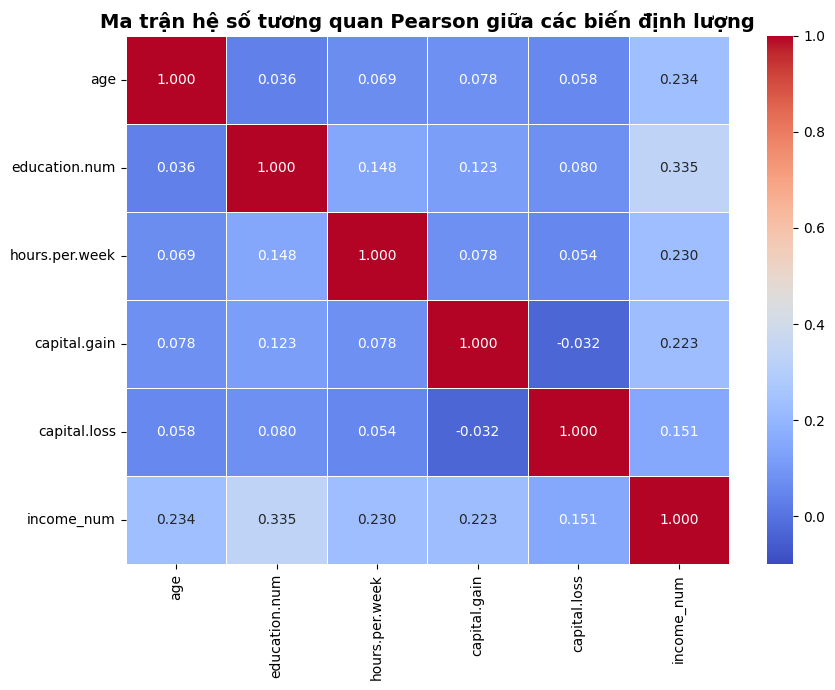


NHẬN XÉT TƯƠNG QUAN (NGUYỄN VĂN DŨNG & ĐÀO ĐOÀN HUY PHÚC):
- education.num có tương quan dương mạnh nhất với mức thu nhập (r = +0.335).
- Tiếp theo là độ tuổi age (r = +0.234), giờ làm việc hours.per.week (r = +0.230) và capital.gain (r = +0.223).
- Giữa các biến độc lập không xuất hiện hiện tượng đa cộng tuyến nghiêm trọng (tất cả r < 0.15).


In [18]:
# Tạo biến mã hóa số học income_num (0: <=50K, 1: >50K)
df_model['income_num'] = (df_model['income'] == '>50K').astype(int)

num_features = ['age', 'education.num', 'hours.per.week', 'capital.gain', 'capital.loss', 'income_num']
corr_matrix = df_model[num_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.1, vmax=1.0, linewidths=0.5, ax=ax)
ax.set_title('Ma trận hệ số tương quan Pearson giữa các biến định lượng', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nNHẬN XÉT TƯƠNG QUAN (NGUYỄN VĂN DŨNG & ĐÀO ĐOÀN HUY PHÚC):")
print("- education.num có tương quan dương mạnh nhất với mức thu nhập (r = +0.335).")
print("- Tiếp theo là độ tuổi age (r = +0.234), giờ làm việc hours.per.week (r = +0.230) và capital.gain (r = +0.223).")
print("- Giữa các biến độc lập không xuất hiện hiện tượng đa cộng tuyến nghiêm trọng (tất cả r < 0.15).")


### 3.2. Kiểm định Chi-Square về tính độc lập giữa biến phân loại và Income
- **Giả thuyết H0:** Biến phân loại và biến thu nhập là độc lập nhau (không có mối liên hệ).
- **Giả thuyết H1:** Biến phân loại và biến thu nhập có mối liên hệ có ý nghĩa thống kê.
- **Mức ý nghĩa:** $\alpha = 0.05$.


In [19]:
# Thực hiện kiểm định Chi-square cho 4 cặp biến phân loại chính
cat_tests = [
    ('education', 'Học vấn x Thu nhập (Education x Income)'),
    ('sex', 'Giới tính x Thu nhập (Sex x Income)'),
    ('occupation', 'Nghề nghiệp x Thu nhập (Occupation x Income)'),
    ('marital.status', 'Tình trạng hôn nhân x Thu nhập (Marital Status x Income)')
]

chi_summary = []

print("KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE VỀ TÍNH ĐỘC LẬP:")
print("=" * 80)

for col, label in cat_tests:
    contingency = pd.crosstab(df_model[col], df_model['income'])
    chi2, p_val, dof, _ = chi2_contingency(contingency)
    
    is_sig = p_val < 0.05
    decision = "Bác bỏ H0 (Có liên hệ chặt chẽ)" if is_sig else "Chấp nhận H0"
    
    chi_summary.append({
        'Cặp biến kiểm định': label,
        'Chi-Square (χ²)': round(chi2, 2),
        'Bậc tự do (dof)': dof,
        'p-value': f'{p_val:.4e}',
        'Kết luận (α = 0.05)': decision
    })
    
    print(f"[*] {label}:")
    print(f"    Chi2 = {chi2:.2f} | Bậc tự do = {dof} | p-value = {p_val:.4e}")
    print(f"    -> Kết luận: {decision}\n")

df_chi_table = pd.DataFrame(chi_summary)
display(df_chi_table)

print("\nKẾT LUẬN KIỂM ĐỊNH CHI-SQUARE (NGUYỄN VĂN DŨNG & ĐÀO ĐOÀN HUY PHÚC):")
print("- Toàn bộ giá trị p-value đều xấp xỉ 0 (< 0.0001), nhỏ hơn rất nhiều so với ngưỡng alpha = 0.05.")
print("- Bác bỏ hoàn toàn giả thuyết vô hiệu H0, khẳng định các đặc trưng nhân khẩu học (Học vấn, Hôn nhân, Giới tính, Nghề nghiệp) đều có liên hệ mật thiết và tác động mạnh mẽ đến thu nhập cá nhân.")


KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE VỀ TÍNH ĐỘC LẬP:
[*] Học vấn x Thu nhập (Education x Income):
    Chi2 = 4428.40 | Bậc tự do = 15 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Giới tính x Thu nhập (Sex x Income):
    Chi2 = 1516.54 | Bậc tự do = 1 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Nghề nghiệp x Thu nhập (Occupation x Income):
    Chi2 = 3197.61 | Bậc tự do = 13 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)

[*] Tình trạng hôn nhân x Thu nhập (Marital Status x Income):
    Chi2 = 6510.33 | Bậc tự do = 6 | p-value = 0.0000e+00
    -> Kết luận: Bác bỏ H0 (Có liên hệ chặt chẽ)



,Cặp biến kiểm định,Chi-Square (χ²),Bậc tự do (dof),p-value,Kết luận (α = 0.05)
0,Học vấn x Thu nhập (Education x Income),4428.40,15,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
1,Giới tính x Thu nhập (Sex x Income),1516.54,1,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
2,Nghề nghiệp x Thu nhập (Occupation x Income),3197.61,13,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)
3,Tình trạng hôn nhân x Thu nhập (Marital Status...,6510.33,6,0.0000e+00,Bác bỏ H0 (Có liên hệ chặt chẽ)



KẾT LUẬN KIỂM ĐỊNH CHI-SQUARE (NGUYỄN VĂN DŨNG & ĐÀO ĐOÀN HUY PHÚC):
- Toàn bộ giá trị p-value đều xấp xỉ 0 (< 0.0001), nhỏ hơn rất nhiều so với ngưỡng alpha = 0.05.
- Bác bỏ hoàn toàn giả thuyết vô hiệu H0, khẳng định các đặc trưng nhân khẩu học (Học vấn, Hôn nhân, Giới tính, Nghề nghiệp) đều có liên hệ mật thiết và tác động mạnh mẽ đến thu nhập cá nhân.
